Dataset shape: (1000, 23)
   ID  Age  Height_cm  Weight_kg   BMI  Cycle_Length_days  \
0   1   24      160.0       47.5  18.6                 28   
1   2   37      162.8       66.0  24.9                 26   
2   3   32      167.9       63.9  22.7                 30   
3   4   28      149.9       60.4  26.9                 33   
4   5   25      159.1       58.9  23.3                 21   

   Period_Duration_days Period_Regularity Pain_Level Bleeding_Level  ...  \
0                     5           Regular       Mild          Heavy  ...   
1                     5         Irregular       Mild         Normal  ...   
2                     4         Irregular   Moderate         Normal  ...   
3                     5           Regular       Mild         Normal  ...   
4                     5         Irregular       Mild         Normal  ...   

  Hair_Loss Weight_Gain Stress_Level Sleep_Hours Exercise_Level Mood_Swings  \
0        No          No     Moderate         6.7       Moderate        

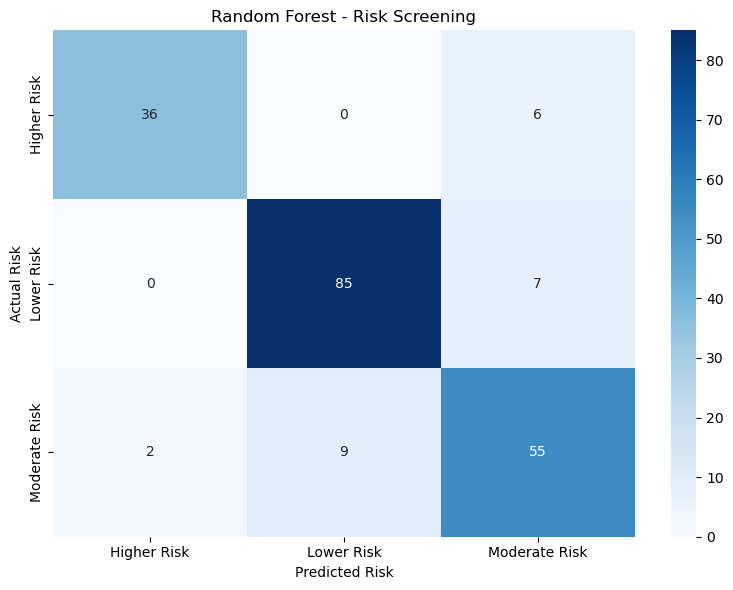


Top 10 important features:
                                     Feature  Importance
8   categorical__Period_Regularity_Irregular    0.122703
9     categorical__Period_Regularity_Regular    0.116376
21       categorical__Excess_Hair_Growth_Yes    0.069594
3                               numeric__BMI    0.066095
20        categorical__Excess_Hair_Growth_No    0.064555
4                 numeric__Cycle_Length_days    0.060192
2                         numeric__Weight_kg    0.056930
7         numeric__Expected_Next_Period_Days    0.044254
6                       numeric__Sleep_Hours    0.036018
26            categorical__Stress_Level_High    0.035866

Model saved successfully!

Example predicted risk: Higher Risk
Higher Risk: 88.00%
Lower Risk: 1.00%
Moderate Risk: 11.00%


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)


df = pd.read_csv(r"C:\Users\Admin\Downloads\synthetic_menstrual_health_1000_rows.csv")

print("Dataset shape:", df.shape)
print(df.head())

df = df.drop_duplicates()
df = df.replace([np.inf, -np.inf], np.nan)

# STEP 4: Select target
target = "PCOS_Risk_Screening"

df = df.dropna(subset=[target])

X = df.drop(columns=[target, "ID"], errors="ignore")
y = df[target]


X = X.drop(columns=["Menstrual_Problem"], errors="ignore")

print("\nTarget distribution:")
print(y.value_counts())

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))

model.fit(X_train, y_train)

print("\nModel training completed successfully!")


y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# STEP 13: Confusion matrix
labels = model.named_steps["classifier"].classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Random Forest - Risk Screening")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.tight_layout()
plt.show()

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = model.named_steps[
    "classifier"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print("\nTop 10 important features:")
print(importance_df.head(10))

joblib.dump(model, "pcos_random_forest.pkl")
print("\nModel saved successfully!")

patient = X_test.iloc[[0]]
prediction = model.predict(patient)[0]

print("\nExample predicted risk:", prediction)

probabilities = model.predict_proba(patient)[0]

for label, probability in zip(labels, probabilities):
    print(f"{label}: {probability * 100:.2f}%")
